# 03 · Offline: building the HR templates

Before generating images, every label map is turned **once** into an **HR template**: a label
map on the HR grid (`template.hr_voxel_mm`), cropped around the brain, with smooth boundaries.
The online generator only reads these templates.

```
label map ─► restrict_labels ─► crop_to_foreground ─► super_resolve ─► HR template (+ record)
```

Code: `nxgen/offline/template.py`; launcher `python -m nxgen.cli.build_templates`.
Config section: `template` (`hr_voxel_mm`, `sigma_mm`, `margin_mm`), plus `labels`.

In [1]:
from _setup import *
from nxgen.offline import template as T
from nxgen.core.io import load_labels
import phantoms

## 1. `restrict_labels`: labels not in the tree

With `labels.unassigned = 'background'`, the launcher passes the tree labels as `allowed`.
Every other label becomes background, and the record lists what was removed. With `'error'`,
nothing is removed here and the generator raises when it meets an unknown label.

In [2]:
seg = np.array([[0, 3, 24], [42, 99, 2]])
out, removed = T.restrict_labels(seg, allowed=[0, 2, 3, 24, 42])
print(out, '\nremoved:', removed)

[[ 0  3 24]
 [42  0  2]] 
removed: [99]


## 2. `crop_to_foreground`: bounding box + margin

The map is cropped to the bounding box of the foreground plus `margin_mm` of background on
every side (one number, or one per axis). Where the margin goes past the edge of the map, the
map is **padded** with background. The affine is updated so the world coordinates do not move.

Why a margin: the deformation (notebook 06) can move the brain a few mm; whatever comes from
outside the template is background. A margin avoids cutting the brain at the border. Bigger
margins cost memory and time in proportion to the number of voxels.

In [3]:
seg = np.zeros((30, 30, 30), int)
seg[2:12, 10:20, 20:29] = 3
crop, aff, box = T.crop_to_foreground(seg, np.eye(4), voxel_mm=1.0, margin_mm=[4, 2, 3])
print('foreground box :', [2, 10, 20], 'to', [12, 20, 29])
print('crop box (input voxels, may be < 0 or > shape = padded):', box)
print('crop shape     :', crop.shape)
print('world position of crop voxel 0:', aff[:3, 3], '(= input voxel', box['lo'], ')')

foreground box : [2, 10, 20] to [12, 20, 29]
crop box (input voxels, may be < 0 or > shape = padded): {'lo': [-2, 8, 17], 'hi': [16, 22, 32]}
crop shape     : (18, 14, 15)
world position of crop voxel 0: [-2.  8. 17.] (= input voxel [-2, 8, 17] )


## 3. `super_resolve`: one-hot → sinc upsampling → Gaussian → argmax

For an input map at voxel `v` and an HR voxel `h` (`v/h` must be an integer, the *upsampling
factor*):

1. each label is turned into a binary (one-hot) channel;
2. the channel is upsampled by **sinc interpolation**: its Fourier spectrum is zero-padded to
   the new size (band-limited interpolation, no blocky staircase);
3. it is multiplied, in Fourier, by the transfer function of a **Gaussian** of std
   `sigma_mm` (smoothing);
4. every HR voxel takes the label with the largest value (**argmax**).

Two tricks keep it affordable with hundreds of labels:

* each label is processed only inside its own bounding box (plus a margin past the kernel);
* the background channel is never computed: upsampling and smoothing are linear and the one-hot
  channels sum to 1, so background = 1 − sum of the others.

With factor 1 and `sigma_mm = 0`, the labels are returned unchanged.

First, on a 2-label phantom, the effect of each part:

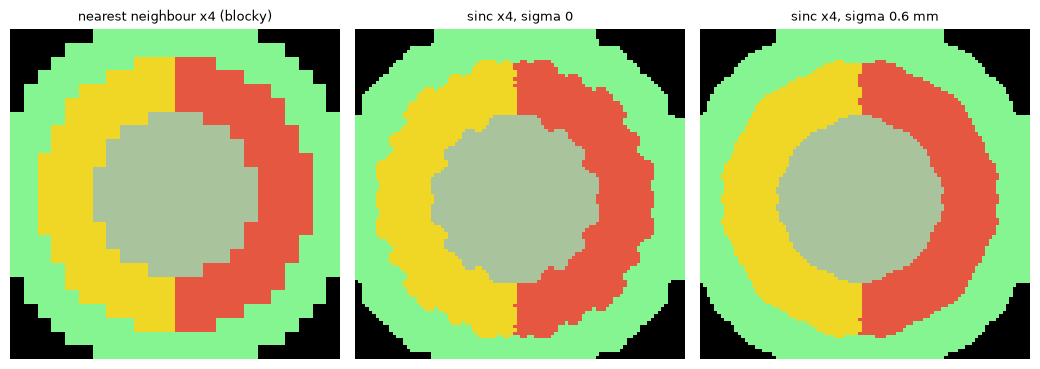

In [4]:
lab = torch.as_tensor(phantoms.sphere_labels((24, 24, 24)))
up_nosmooth = T.super_resolve(lab, factor=4, voxel_mm=1.0, sigma_mm=0.0)
up_smooth = T.super_resolve(lab, factor=4, voxel_mm=1.0, sigma_mm=0.6)
nearest = lab.repeat_interleave(4, 0).repeat_interleave(4, 1).repeat_interleave(4, 2)
show([nearest, up_nosmooth, up_smooth],
     ['nearest neighbour x4 (blocky)', 'sinc x4, sigma 0', 'sinc x4, sigma 0.6 mm'], size=3.5)

Sinc interpolation removes the staircase; the Gaussian additionally rounds corners and thin
protrusions. Too much smoothing deletes thin structures. The build record reports this (below).

The upsampling itself, on one channel (`sinc_upsample_smooth`):

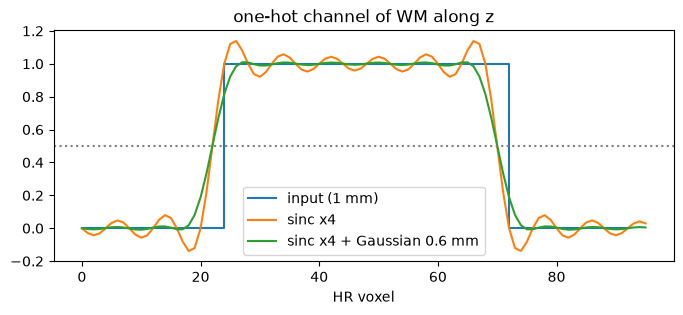

In [5]:
mask = (lab == phantoms.WM).float()
profile_lo = mask[12, 12, :]
hr = T.sinc_upsample_smooth(mask, 4, 0.0, 0.25)[48, 48, :]
hr_s = T.sinc_upsample_smooth(mask, 4, 0.6, 0.25)[48, 48, :]
plt.figure(figsize=(8, 3))
plt.step(np.arange(24) * 4, profile_lo, where='post', label='input (1 mm)')
plt.plot(np.arange(96), hr, label='sinc x4')
plt.plot(np.arange(96), hr_s, label='sinc x4 + Gaussian 0.6 mm')
plt.axhline(0.5, color='gray', ls=':')
plt.legend(); plt.xlabel('HR voxel'); plt.title('one-hot channel of WM along z'); plt.show()

Sinc interpolation rings (Gibbs) near edges; the argmax ignores the small ripples, and the
Gaussian damps them.

## 4. `build_template`: everything together, with a cache and a record

`build_template(seg_path, out_dir, hr_voxel_mm, sigma_mm, margin_mm, allowed, background, device)`
writes:

* `<name>_hr<voxel>mm.nii.gz`: the HR template (raw label values, uint16);
* `<name>_hr<voxel>mm.json`: the **build record**.

A template is reused if its record has the same source hash (SHA-256 of the input file) and
the same settings. Otherwise it is rebuilt.

In [6]:
demo_dir = os.path.join(OUTPUTS, 'templates_demo')
path, record = T.build_template(SOURCE_MAP, demo_dir, hr_voxel_mm=0.1, sigma_mm=0.1,
                                margin_mm=4.0, allowed=None, background=0, device=DEVICE)
print(path)

/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/outputs/notebooks/templates_demo/case-1_hr0.1mm.nii.gz: reused (same source and settings)
/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/outputs/notebooks/templates_demo/case-1_hr0.1mm.nii.gz


Calling it again with the same source and settings reuses the file (no work):

In [7]:
path, record = T.build_template(SOURCE_MAP, demo_dir, hr_voxel_mm=0.2, sigma_mm=0.1,
                                margin_mm=4.0, allowed=None, background=0, device=DEVICE)

/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/outputs/notebooks/templates_demo/case-1_hr0.2mm.nii.gz: reused (same source and settings)


The launcher is the normal way to build templates. It reads the settings from the config and,
with `labels.unassigned = 'background'`, passes the tree labels as `allowed`:

```bash
python -m nxgen.cli.build_templates --config configs/nextbrain.json \
    --seg ../generator_v2/data/inputs/case-1.nii.gz --out data/templates --device cuda:0
```

The template used by all notebooks was built this way, so this call just reuses it:

In [8]:
from nxgen.cli import build_templates
build_templates.main(['--config', CONFIG, '--seg', SOURCE_MAP, '--out', TEMPLATE_DIR,
                      '--device', DEVICE])

# Me quede aqui

/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/templates/case-1_hr0.2mm.nii.gz: reused (same source and settings)
/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/templates/case-1_hr0.2mm.nii.gz: shape [477, 877, 578], removed labels [], vanished labels []


In [9]:
from nxgen.core.io import load_json
record = load_json(TEMPLATE.replace('.nii.gz', '.json'))
print({k: v for k, v in record.items() if not k.startswith('volumes')})

{'source': '/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2/data/inputs/case-1.nii.gz', 'source_sha256': '1160dccf537e84acf7e4cdb7b35698ff2693412fc7fca6d158051e0b7aee557f', 'settings': {'hr_voxel_mm': 0.2, 'sigma_mm': 0.1, 'margin_mm': 4.0, 'background': 0, 'allowed': [0, 7, 48, 50, 68, 79, 99, 100, 101, 102, 103, 108, 111, 113, 114, 117, 118, 119, 120, 125, 128, 130, 147, 149, 150, 157, 160, 161, 174, 181, 184, 190, 191, 192, 193, 194, 196, 199, 201, 206, 207, 208, 209, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 232, 234, 238, 240, 242, 243, 244, 245, 246, 252, 253, 254, 255, 256, 268, 274, 275, 276, 277, 278, 279, 282, 283, 284, 285, 286, 295, 297, 298, 301, 303, 304, 305, 306, 307, 308, 309, 310, 312, 313, 314, 315, 316, 320, 321, 322, 326, 339, 340, 341, 342, 343, 344, 345, 346, 347, 349, 350, 352, 354, 364, 365, 367, 368, 369, 370, 371, 372, 373, 374, 375, 377, 378, 379, 380, 381, 382, 384, 385, 386, 393, 394, 395, 396, 3

The record contains:

| key | meaning |
|---|---|
| `source`, `source_sha256` | the input file and its hash (detects a changed file with the same name) |
| `settings` | `hr_voxel_mm`, `sigma_mm`, `margin_mm`, `background`, `allowed` |
| `input_voxel_mm`, `upsampling_factor` | input voxel and `input / HR` |
| `crop_box`, `shape` | crop in input voxels and HR shape |
| `removed_labels` | labels sent to background by `restrict_labels` |
| `volumes_in_mm3`, `volumes_out_mm3` | volume of every label before and after |
| `vanished_labels` | labels present before, absent after (thin/tiny structures can vanish) |

The per-label volume change shows which structures the super-resolution affects most:

volume ratio after/before: median 0.9999, min 0.877, max 1.013


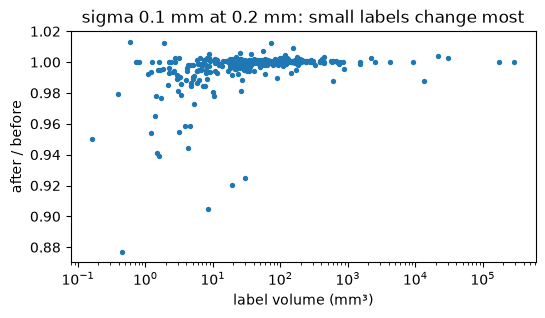

In [10]:
vin = {int(k): v for k, v in record['volumes_in_mm3'].items()}
vout = {int(k): v for k, v in record['volumes_out_mm3'].items()}
ratio = {k: vout.get(k, 0) / v for k, v in vin.items()}
r = np.array(list(ratio.values()))
print(f'volume ratio after/before: median {np.median(r):.4f}, min {r.min():.3f}, max {r.max():.3f}')
plt.figure(figsize=(6, 3))
plt.scatter(list(vin.values()), r, s=8)
plt.xscale('log'); plt.xlabel('label volume (mm³)'); plt.ylabel('after / before')
plt.title('sigma 0.1 mm at 0.2 mm: small labels change most'); plt.show()

## 5. The template on disk

source  : (467, 923, 589) voxel 0.2 mm
template: (477, 877, 578) voxel [0.2 0.2 0.2] (cropped with a 4 mm margin)


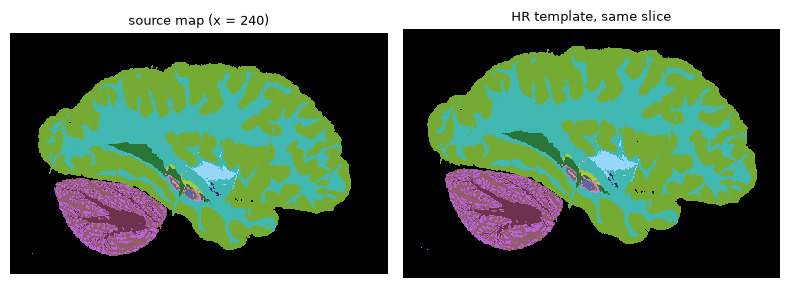

In [11]:
hr, hr_affine, hr_voxel = load_labels(TEMPLATE)
src, src_affine, _ = load_labels(SOURCE_MAP)
print('source  :', src.shape, 'voxel 0.2 mm')
print('template:', hr.shape, 'voxel', hr_voxel, '(cropped with a 4 mm margin)')
lo = record['crop_box']['lo']
x = 240
show([torch.as_tensor(src[x]), torch.as_tensor(hr[x - lo[0]])],
     ['source map (x = 240)', 'HR template, same slice'], labels=[True, True], size=4)

## 6. Rules and errors

* Input voxels must be **isotropic** and an **integer multiple** of `hr_voxel_mm`
  (0.4 mm → 0.2 mm is fine, 0.3 mm → 0.2 mm is not).
* A map with no foreground raises a clear error.
* The template is **not** padded to the partial-volume factor here: it does not depend on the
  output resolution. The generator pads it when it loads it (notebook 10), so one template
  serves 0.2, 0.4, 0.6 ... mm outputs.

In [12]:
folder = phantoms.workdir()
p = os.path.join(folder, 'map.nii.gz')
from nxgen.core.io import save_labels
save_labels(phantoms.sphere_labels((20, 20, 20)), np.diag([0.3, 0.3, 0.3, 1]), p)
try:
    T.build_template(p, folder, hr_voxel_mm=0.2)
except ValueError as e:
    print('error:', e)
save_labels(np.zeros((5, 5, 5), int), np.eye(4), p)
try:
    T.build_template(p, folder, hr_voxel_mm=1.0)
except ValueError as e:
    print('error:', e)

error: /tmp/tmpdxapb5dt/map.nii.gz: voxel 0.3 mm is not an integer multiple of the HR voxel 0.2 mm
error: The label map has no foreground (only background)


## 7. Differences with v2

* Parametrised by the HR voxel only, not by `target_voxel / factor`.
* Fixed margins only. v2's automatic margins (`"auto"`, `{"auto": q}`) were removed: they
  were complex and not exact (`problems_to_solve.md` #6-8).
* The cache checks the source hash, not only the file name (`problems_to_solve.md` #3).
* The algorithm of `super_resolve` is the same as v2's `super_resolve_labels`, and the tests
  check that both give **identical** results (`tests/test_template.py`).